# Análisis exploratorio — Demanda de tecnologías y competencias
Preguntas que responde este notebook, dentro del proyecto de residencias profesionales:
1. ¿Qué **tecnologías** y **competencias** piden más las empresas?
2. ¿Cambia la demanda en los **puestos de nivel inicial** (los más cercanos a un residente)?
3. ¿Cambia según el **país** o la **modalidad**?
4. ¿Qué habilidades se piden **juntas**? (base para recomendar proyectos y rutas de aprendizaje)

Datos de entrada: `data/processed/`, generados en `inspeccion_limpieza.ipynb`.

In [1]:
#importar las librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator, PercentFormatter

In [2]:
#Cargar los datos limpios
carpeta_processed = "../../data/processed"
vacantes = pd.read_csv(f"{carpeta_processed}/vacantes_limpio.csv")
vacante_habilidad = pd.read_csv(f"{carpeta_processed}/vacantes_habilidades.csv")
catalogo = pd.read_csv(f"{carpeta_processed}/catalogo_habilidades.csv")

print(f"Vacantes: {len(vacantes):,} | Pares vacante-habilidad: {len(vacante_habilidad):,}")
vacantes.head(3)

Vacantes: 6,489 | Pares vacante-habilidad: 90,064


,id_vacante,titulo,empresa,ubicacion,pais,nivel,modalidad,habilidades,num_habilidades,es_puesto_inicial
0,1,C# Software Engineer,E Tech Group,"West Chester, OH",Estados Unidos,Asociado,Remoto,C#; .NET; WPF; ASP.NET MVC; Web API; C++; SQL ...,13,True
1,2,Software Implementation Engineer,Kardex,"Cincinnati, OH",Estados Unidos,Asociado,Remoto,Software Implementation; Software Testing; Sof...,7,True
2,3,"Senior Software Engineer, Back End (Go, AWS, J...",Jobs for Humanity,"Chattanooga, TN",Estados Unidos,Intermedio-Senior,Presencial,Java; Python; SQL; Node.js; Go; Scala; AWS; GC...,12,False


In [3]:
#Colores y estilo de las graficas
COLOR_PRINCIPAL = "#2a78d6"
COLOR_SECUNDARIO = "#eb6834"
COLOR_FONDO = "#fcfcfb"
COLOR_TEXTO = "#0b0b0b"
COLOR_TEXTO_SEC = "#52514e"
COLOR_MUTED = "#898781"

plt.rcParams.update({
    "figure.facecolor": COLOR_FONDO,
    "axes.facecolor": COLOR_FONDO,
    "savefig.facecolor": COLOR_FONDO,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": COLOR_TEXTO_SEC,
    "axes.titlecolor": COLOR_TEXTO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "xtick.color": COLOR_MUTED,
    "ytick.color": COLOR_MUTED,
    "xtick.labelcolor": COLOR_TEXTO_SEC,
    "ytick.labelcolor": COLOR_TEXTO_SEC,
    "text.color": COLOR_TEXTO,
    "font.size": 10,
    "legend.frameon": False,
    "figure.dpi": 110,
})

#Escala secuencial (un solo tono, de claro a oscuro) para los mapas de calor
cmap_azul = LinearSegmentedColormap.from_list("azul", ["#f0efec", "#9ec5f4", "#2a78d6", "#104281"])

def titulo_figura(fig, texto):
    fig.suptitle(texto, x=0.01, ha="left", fontsize=14, fontweight="bold")

def barras_horizontales(ax, serie, color=COLOR_PRINCIPAL, formato="{:.0%}"):
    #Barras ordenadas de mayor a menor (la mayor arriba) con su valor al final
    serie = serie.sort_values()
    ax.barh(serie.index, serie.values, color=color, height=0.65)
    for i, valor in enumerate(serie.values):
        ax.text(valor + serie.max() * 0.01, i, formato.format(valor), va="center", fontsize=9, color=COLOR_TEXTO_SEC)
    ax.set_xlim(0, serie.max() * 1.18)
    ax.grid(axis="y", visible=False)
    ax.set_ylabel("")

def eje_porcentaje(ax, maximo):
    #Marcas cada 1, 2, 5, 10 o 20 puntos porcentuales segun el rango, sin decimales
    paso = next(p for p in [0.01, 0.02, 0.05, 0.1, 0.2] if maximo / p <= 6)
    ax.xaxis.set_major_locator(MultipleLocator(paso))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))

In [4]:
#Grupos de categorias
categorias_tecnicas = [
    "Lenguajes", "Frameworks y librerías", "Cloud", "DevOps e infraestructura", "Bases de datos",
    "Datos e IA", "Arquitectura y buenas prácticas", "Sistemas embebidos", "Desarrollo móvil",
]
total_vacantes = len(vacantes)

#Porcentaje de vacantes que piden cada habilidad
pct_habilidad = (
    vacante_habilidad.groupby(["habilidad", "categoria"])["id_vacante"].nunique()
    .div(total_vacantes).rename("pct_vacantes").reset_index()
    .sort_values("pct_vacantes", ascending=False)
)
tecnologias = pct_habilidad[pct_habilidad["categoria"].isin(categorias_tecnicas)]

## 1. Panorama de las vacantes

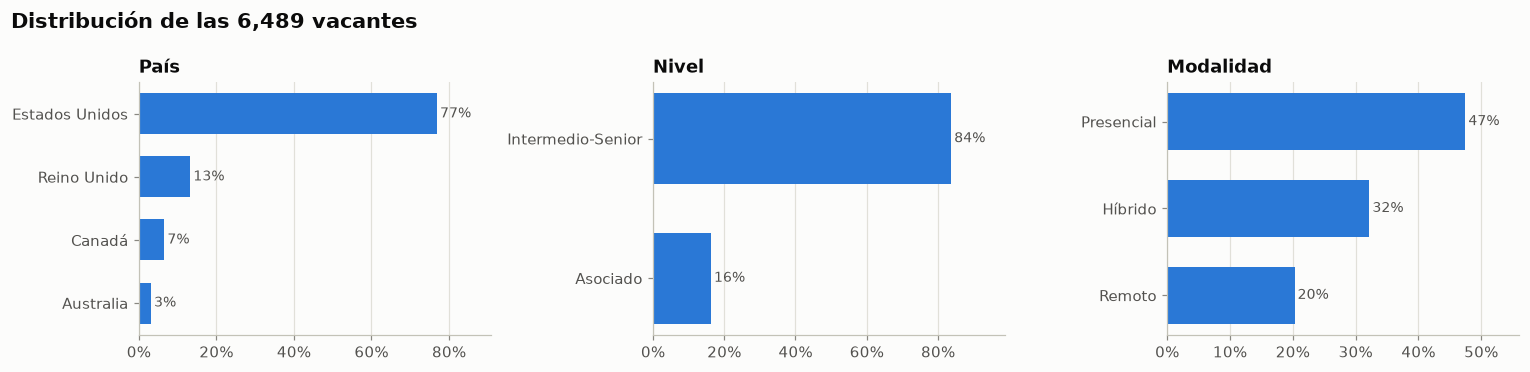

Puestos de nivel inicial: 1,101 (17.0%)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, (col, nombre) in zip(axes, {"pais": "País", "nivel": "Nivel", "modalidad": "Modalidad"}.items()):
    serie = vacantes[col].value_counts(normalize=True)
    barras_horizontales(ax, serie)
    eje_porcentaje(ax, serie.max())
    ax.set_title(nombre)
titulo_figura(fig, f"Distribución de las {total_vacantes:,} vacantes")
fig.tight_layout()
plt.show()

print(f"Puestos de nivel inicial: {vacantes['es_puesto_inicial'].sum():,} ({vacantes['es_puesto_inicial'].mean():.1%})")

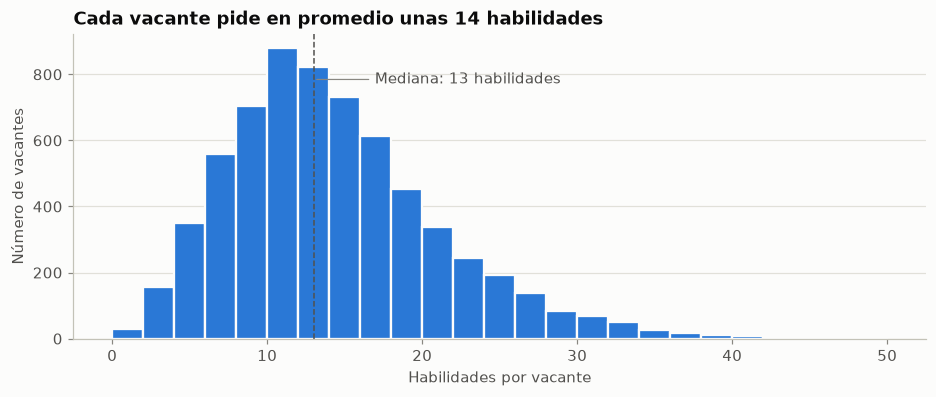

In [6]:
#Numero de habilidades que pide cada vacante
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(vacantes["num_habilidades"], bins=range(0, 52, 2), color=COLOR_PRINCIPAL, edgecolor=COLOR_FONDO, linewidth=1.5)
mediana = vacantes["num_habilidades"].median()
ax.axvline(mediana, color=COLOR_TEXTO_SEC, linestyle="--", linewidth=1)
ax.annotate(f"Mediana: {mediana:.0f} habilidades", xy=(mediana, ax.get_ylim()[1] * 0.85), xytext=(40, 0),
            textcoords="offset points", va="center", color=COLOR_TEXTO_SEC,
            arrowprops={"arrowstyle": "-", "color": COLOR_MUTED, "linewidth": 0.8})
ax.grid(axis="x", visible=False)
ax.set_xlabel("Habilidades por vacante")
ax.set_ylabel("Número de vacantes")
ax.set_title("Cada vacante pide en promedio unas 14 habilidades")
plt.show()

## 2. Demanda por categoría
Porcentaje de vacantes que piden **al menos una** habilidad de cada categoría.

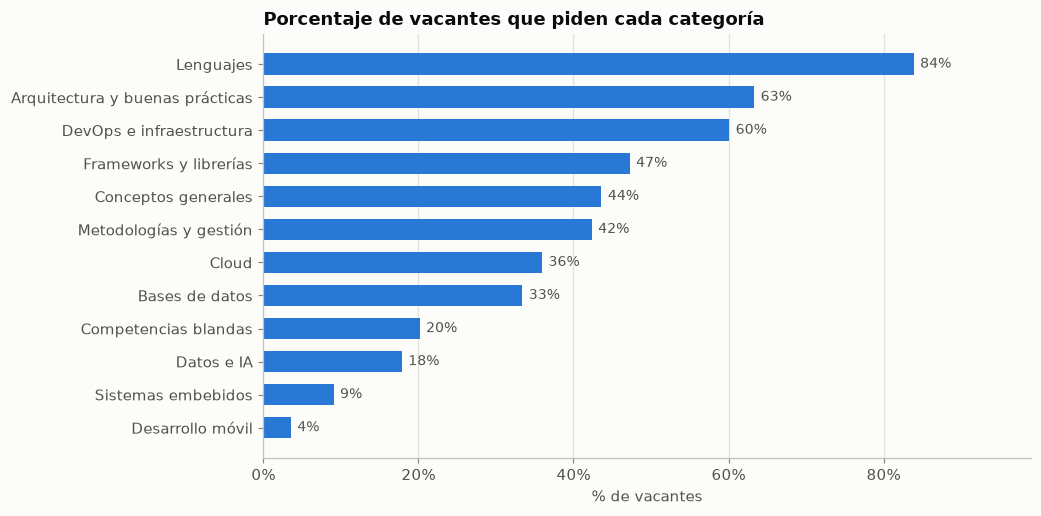

In [7]:
pct_categoria = (
    vacante_habilidad[vacante_habilidad["categoria"] != "Sin clasificar"]
    .groupby("categoria")["id_vacante"].nunique().div(total_vacantes)
)

fig, ax = plt.subplots(figsize=(9, 5))
barras_horizontales(ax, pct_categoria)
eje_porcentaje(ax, pct_categoria.max())
ax.set_xlabel("% de vacantes")
ax.set_title("Porcentaje de vacantes que piden cada categoría")
plt.show()

## 3. Tecnologías más demandadas
Se excluyen las competencias blandas, las metodologías y los conceptos generales (como *Software Engineering*), que se analizan aparte.

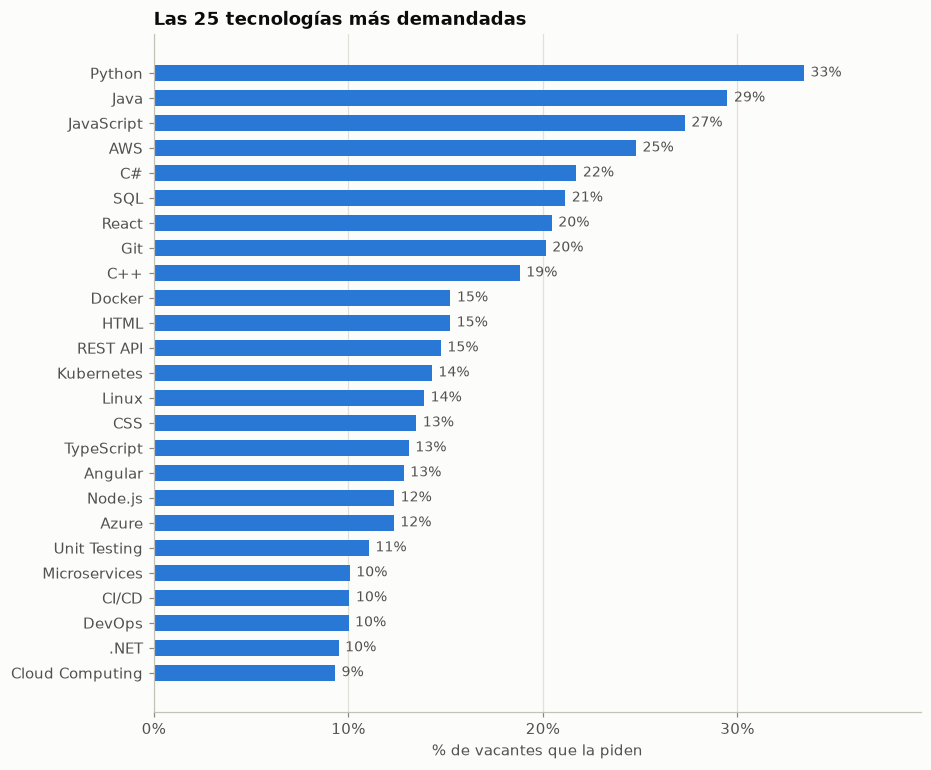

In [8]:
top_tecnologias = tecnologias.head(25).set_index("habilidad")["pct_vacantes"]

fig, ax = plt.subplots(figsize=(9, 8))
barras_horizontales(ax, top_tecnologias)
eje_porcentaje(ax, top_tecnologias.max())
ax.set_xlabel("% de vacantes que la piden")
ax.set_title("Las 25 tecnologías más demandadas")
plt.show()

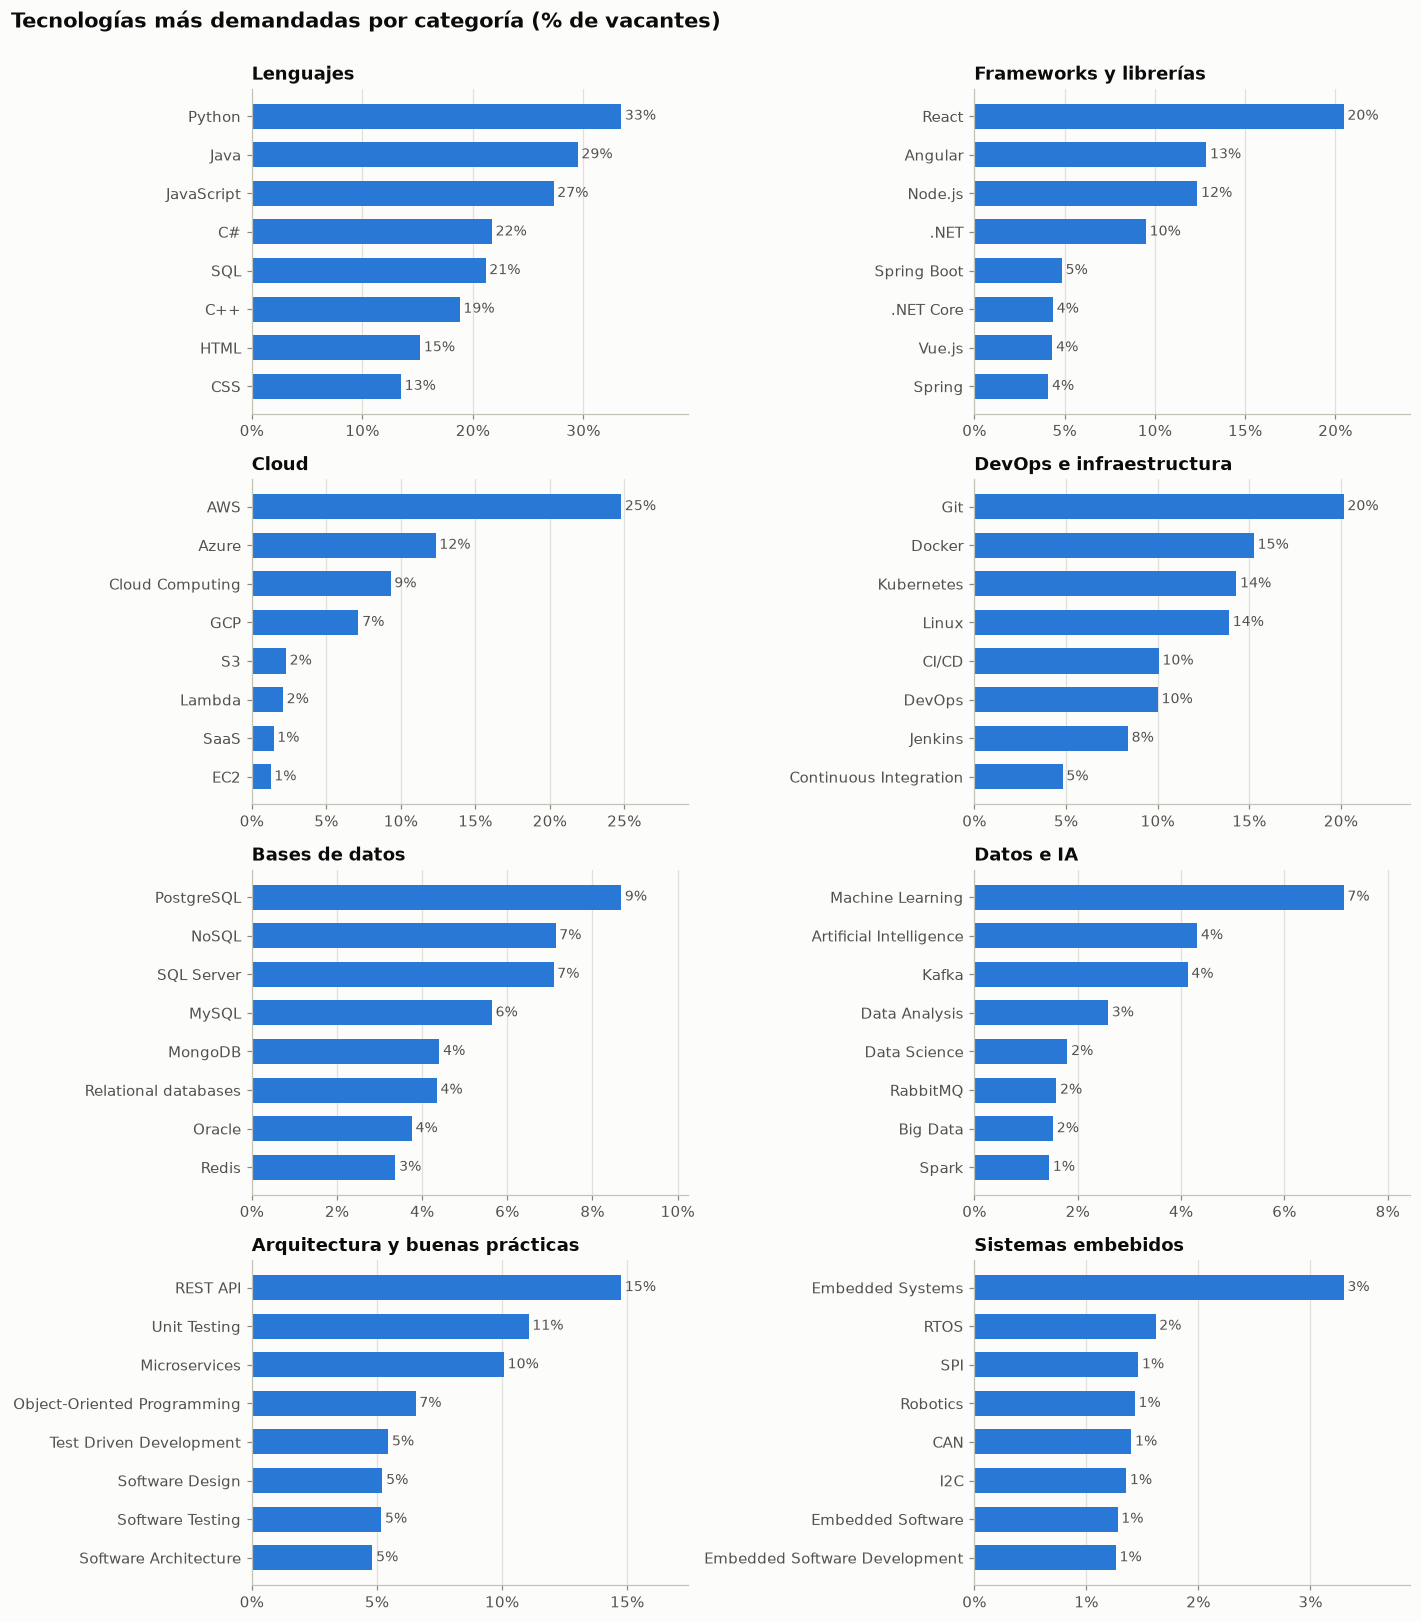

In [9]:
#Top de cada categoria tecnica
categorias_grafica = [c for c in categorias_tecnicas if c != "Desarrollo móvil"]

fig, axes = plt.subplots(4, 2, figsize=(13, 15))
for ax, categoria in zip(axes.flat, categorias_grafica):
    top = tecnologias[tecnologias["categoria"] == categoria].head(8).set_index("habilidad")["pct_vacantes"]
    barras_horizontales(ax, top)
    eje_porcentaje(ax, top.max())
    ax.set_title(categoria)
titulo_figura(fig, "Tecnologías más demandadas por categoría (% de vacantes)")
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

## 4. Competencias blandas y metodologías

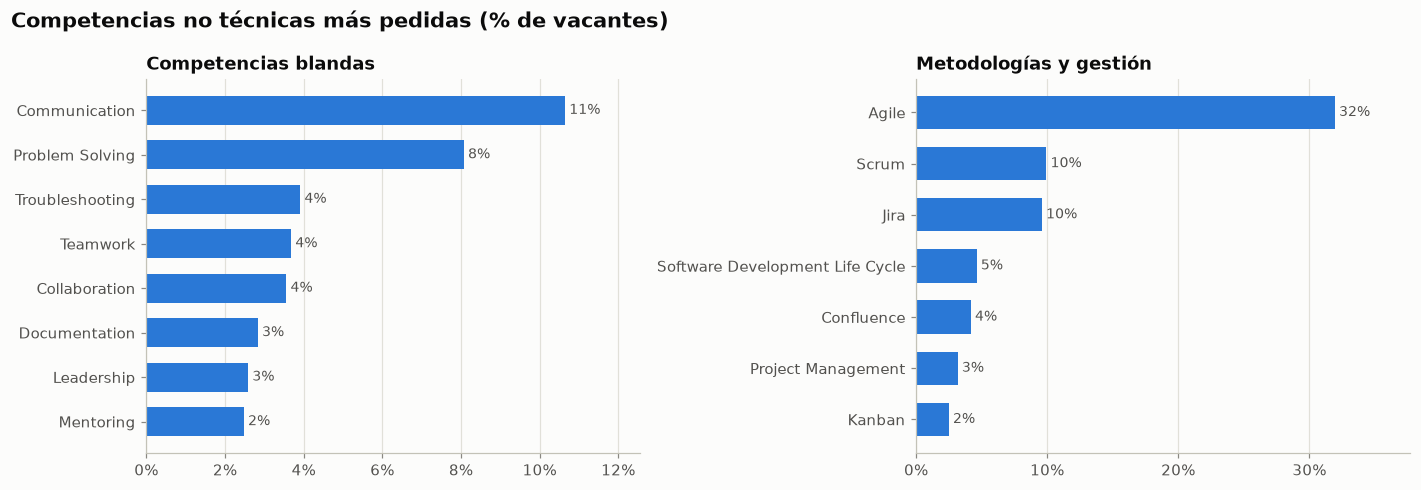

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, categoria in zip(axes, ["Competencias blandas", "Metodologías y gestión"]):
    top = pct_habilidad[pct_habilidad["categoria"] == categoria].head(8).set_index("habilidad")["pct_vacantes"]
    barras_horizontales(ax, top)
    eje_porcentaje(ax, top.max())
    ax.set_title(categoria)
titulo_figura(fig, "Competencias no técnicas más pedidas (% de vacantes)")
fig.tight_layout()
plt.show()

Las competencias blandas aparecen en menos vacantes que las tecnologías. Esto **no** significa que importen menos: muchas empresas las describen en el texto de la vacante en lugar de listarlas como habilidad.

## 5. Puestos de nivel inicial vs. Intermedio-Senior
Los residentes buscan puestos de entrada. ¿Se piden las mismas tecnologías?

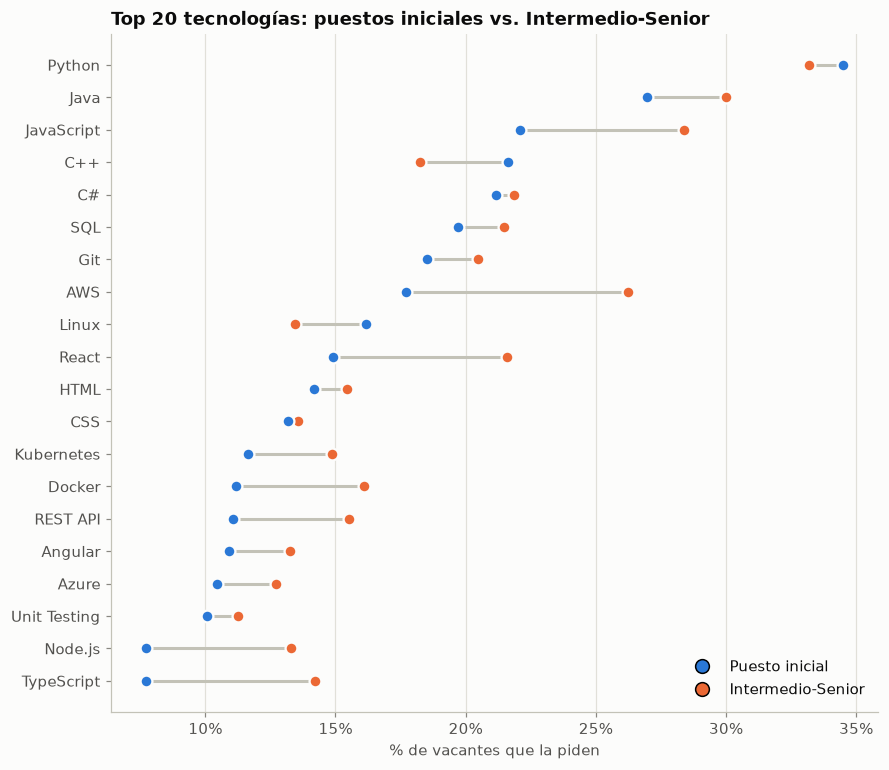

In [11]:
def pct_por_grupo(mascara):
    ids = vacantes.loc[mascara, "id_vacante"]
    subconjunto = vacante_habilidad[vacante_habilidad["id_vacante"].isin(ids)]
    return subconjunto.groupby("habilidad")["id_vacante"].nunique() / len(ids)

pct_inicial = pct_por_grupo(vacantes["es_puesto_inicial"])
pct_resto = pct_por_grupo(~vacantes["es_puesto_inicial"])

comparacion_nivel = pd.DataFrame({"Puesto inicial": pct_inicial, "Intermedio-Senior": pct_resto}).fillna(0)
comparacion_nivel = comparacion_nivel.loc[tecnologias.head(20)["habilidad"]]
comparacion_nivel["diferencia"] = comparacion_nivel["Puesto inicial"] - comparacion_nivel["Intermedio-Senior"]
orden = comparacion_nivel.sort_values("Puesto inicial")

fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(orden))
ax.hlines(y, orden["Puesto inicial"], orden["Intermedio-Senior"], color="#c3c2b7", linewidth=2)
ax.scatter(orden["Intermedio-Senior"], y, s=60, color=COLOR_SECUNDARIO, edgecolor=COLOR_FONDO, linewidth=1.5, zorder=3)
ax.scatter(orden["Puesto inicial"], y, s=60, color=COLOR_PRINCIPAL, edgecolor=COLOR_FONDO, linewidth=1.5, zorder=3)
ax.set_yticks(y, orden.index)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
ax.set_xlabel("% de vacantes que la piden")
ax.legend(handles=[
    Line2D([0], [0], marker="o", color="none", markerfacecolor=COLOR_PRINCIPAL, markersize=9, label="Puesto inicial"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=COLOR_SECUNDARIO, markersize=9, label="Intermedio-Senior"),
], loc="lower right")
ax.set_title("Top 20 tecnologías: puestos iniciales vs. Intermedio-Senior")
plt.show()

In [12]:
#Tecnologias con mayor diferencia entre niveles (puntos porcentuales)
(comparacion_nivel.sort_values("diferencia") * 100).round(1)

,Puesto inicial,Intermedio-Senior,diferencia
habilidad,,,
AWS,17.7,26.2,-8.5
React,14.9,21.6,-6.7
TypeScript,7.7,14.2,-6.5
JavaScript,22.1,28.4,-6.3
Node.js,7.7,13.3,-5.6
Docker,11.2,16.1,-4.9
REST API,11.1,15.5,-4.4
Kubernetes,11.6,14.8,-3.2
Java,27.0,30.0,-3.0


## 6. Diferencias por país

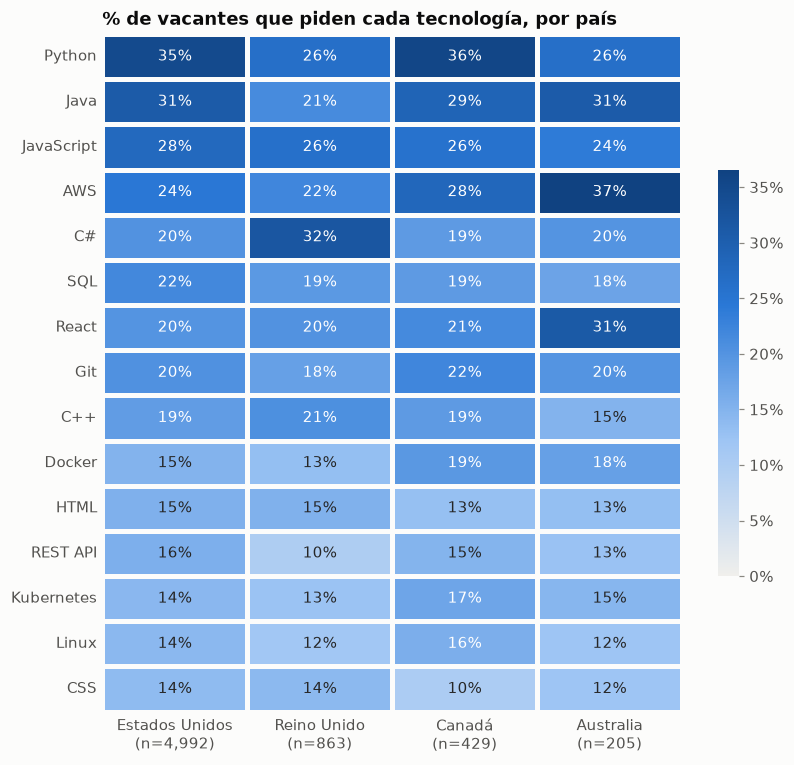

In [13]:
top15 = tecnologias.head(15)["habilidad"]
paises = vacantes["pais"].value_counts().index

pct_pais = pd.DataFrame({pais: pct_por_grupo(vacantes["pais"] == pais) for pais in paises}).fillna(0).loc[top15]
pct_pais.columns = [f"{pais}\n(n={(vacantes['pais'] == pais).sum():,})" for pais in paises]

fig, ax = plt.subplots(figsize=(8.5, 8))
sns.heatmap(pct_pais, cmap=cmap_azul, vmin=0, vmax=pct_pais.values.max(), annot=True, fmt=".0%",
            linewidths=2, linecolor=COLOR_FONDO, cbar_kws={"format": PercentFormatter(1, decimals=0), "shrink": 0.6}, ax=ax)
ax.grid(False)
ax.tick_params(length=0)
ax.set_ylabel("")
ax.set_title("% de vacantes que piden cada tecnología, por país")
plt.show()

## 7. Modalidad de trabajo

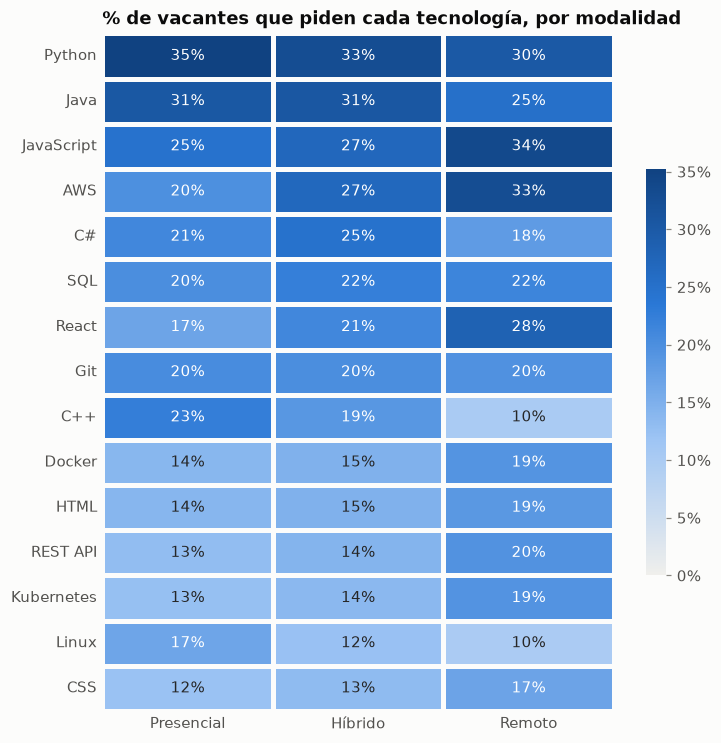

In [14]:
pct_modalidad = pd.DataFrame({m: pct_por_grupo(vacantes["modalidad"] == m)
                              for m in ["Presencial", "Híbrido", "Remoto"]}).fillna(0).loc[top15]

fig, ax = plt.subplots(figsize=(7.5, 8))
sns.heatmap(pct_modalidad, cmap=cmap_azul, vmin=0, vmax=pct_modalidad.values.max(), annot=True, fmt=".0%",
            linewidths=2, linecolor=COLOR_FONDO, cbar_kws={"format": PercentFormatter(1, decimals=0), "shrink": 0.6}, ax=ax)
ax.grid(False)
ax.tick_params(length=0)
ax.set_ylabel("")
ax.set_title("% de vacantes que piden cada tecnología, por modalidad")
plt.show()

## 8. Habilidades que se piden juntas
Se lee por filas: **de las vacantes que piden la tecnología de la fila, qué porcentaje pide también la de la columna**.
Esta información es la base del recomendador: si un alumno sabe *React*, ¿qué le conviene aprender después?

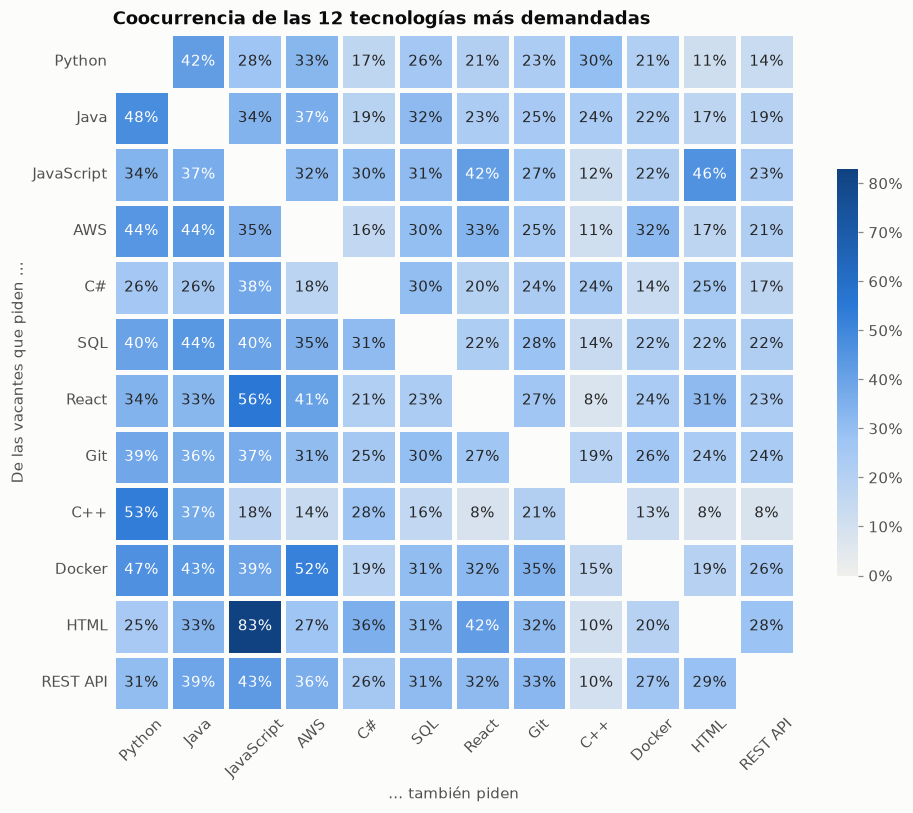

In [15]:
top12 = tecnologias.head(12)["habilidad"].tolist()

#Matriz binaria: una fila por vacante, una columna por tecnologia (1 si la pide)
matriz = pd.crosstab(vacante_habilidad["id_vacante"], vacante_habilidad["habilidad"])
matriz = (matriz[top12] > 0).astype(int)

coocurrencia = matriz.T @ matriz
condicional = coocurrencia.div(np.diag(coocurrencia), axis=0)
#La diagonal (una tecnologia consigo misma) siempre es 100 %: se oculta
condicional = condicional.mask(np.eye(len(top12), dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(condicional, cmap=cmap_azul, vmin=0, vmax=np.nanmax(condicional.values), annot=True, fmt=".0%",
            linewidths=2, linecolor=COLOR_FONDO, cbar_kws={"format": PercentFormatter(1, decimals=0), "shrink": 0.6}, ax=ax)
ax.grid(False)
ax.tick_params(length=0)
ax.tick_params(axis="y", labelrotation=0)
ax.tick_params(axis="x", labelrotation=45)
ax.set_xlabel("... también piden")
ax.set_ylabel("De las vacantes que piden ...")
ax.set_title("Coocurrencia de las 12 tecnologías más demandadas")
plt.show()

In [16]:
#Parejas de tecnologias mas asociadas (lift > 1: aparecen juntas mas de lo esperado por azar)
top50 = tecnologias.head(50)["habilidad"].tolist()
matriz50 = (pd.crosstab(vacante_habilidad["id_vacante"], vacante_habilidad["habilidad"])[top50] > 0).astype(int)
conjunta = (matriz50.T @ matriz50) / len(matriz50)
soporte = matriz50.mean()

parejas = []
for i, a in enumerate(top50):
    for b in top50[i + 1:]:
        vacantes_juntas = int(conjunta.loc[a, b] * len(matriz50))
        if vacantes_juntas >= 100:
            parejas.append({"tecnologia_a": a, "tecnologia_b": b, "vacantes_juntas": vacantes_juntas,
                            "lift": conjunta.loc[a, b] / (soporte[a] * soporte[b])})

pd.DataFrame(parejas).sort_values("lift", ascending=False).head(15).round(2).reset_index(drop=True)

,tecnologia_a,tecnologia_b,vacantes_juntas,lift
0,Data structures,Algorithms,223,16.89
1,HTML,CSS,815,6.10
2,Azure,GCP,309,5.38
3,SQL Server,.NET Core,102,5.08
4,Docker,Kubernetes,655,4.63
5,Angular,Vue.js,160,4.43
6,PostgreSQL,MongoDB,108,4.35
7,C++,C,341,4.31
8,PostgreSQL,MySQL,129,4.06
9,Kubernetes,Terraform,156,3.64


## 9. Empresas con más vacantes

In [17]:
vacantes["empresa"].value_counts().head(10)

empresa
IP Recruiter Group                         99
Jobs for Humanity                          86
ClearanceJobs                              86
Northrop Grumman                           82
Get It Recruit - Information Technology    70
Energy Jobline                             70
Steneral Consulting                        44
Motion Recruitment                         44
CyberCoders                                36
Abbott                                     33
Name: count, dtype: int64

## 10. Conclusiones

**Tecnologías más demandadas** (6,489 perfiles de puesto únicos):
- **Lenguajes:** aparecen en el 84 % de las vacantes. Python (33 %), Java (29 %) y JavaScript (27 %) dominan; les siguen C# (22 %), SQL (21 %) y C++ (19 %).
- **Cloud:** AWS (25 %) duplica a Azure (12 %) y casi cuadruplica a GCP (7 %).
- **DevOps:** Git (20 %), Docker (15 %) y Kubernetes (14 %) son ya parte del perfil estándar del desarrollador.
- **Frameworks:** React (20 %) es el más pedido, por delante de Angular (13 %) y Node.js (12 %).
- **Arquitectura:** REST API (15 %), pruebas unitarias (11 %) y microservicios (10 %).

**Competencias no técnicas**
- **Agile** aparece en el 32 % de las vacantes: es la competencia no técnica más pedida.
- Las competencias blandas (comunicación 11 %, resolución de problemas 8 %) se listan poco porque suelen describirse en el texto de la vacante.

**Puestos de nivel inicial** (los más cercanos a un residente)
- Piden **menos tecnologías de cloud y de frontend moderno**: AWS (−8.5 puntos), React (−6.7), TypeScript (−6.5).
- Piden **un poco más de fundamentos**: C++ (+3.4), Linux (+2.7) y Python (+1.3).
- Conclusión práctica: para un residente pesan más los lenguajes y los fundamentos que las herramientas especializadas.

**País y modalidad**
- Reino Unido destaca en C# (32 %); Australia en AWS (37 %) y React (31 %).
- Las vacantes **remotas** piden más JavaScript (34 %), React (28 %) y AWS (33 %); C++ casi no aparece en remoto (10 % vs. 23 % presencial), por su vínculo con sistemas embebidos y hardware.

**Habilidades que se piden juntas** (base del recomendador)
- El 83 % de las vacantes con HTML piden también JavaScript, y el 56 % de las que piden React.
- El 52 % de las vacantes con Docker piden AWS; el 53 % de las de C++ piden Python.
- Parejas más asociadas: Data structures + Algorithms, HTML + CSS, Docker + Kubernetes, C# + .NET, Microservices + Spring Boot.

**Limitaciones**
- Mercado de Estados Unidos, Reino Unido, Canadá y Australia, con una sola fecha (diciembre de 2023): sirve como referencia, no refleja el mercado local.
- El 30 % de las menciones quedó *Sin clasificar* (habilidades poco frecuentes o muy específicas).

**Siguiente paso:** usar la coocurrencia y las categorías para construir el **recomendador** (habilidades del alumno → proyectos afines y habilidades que le faltan).